In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
garmin = pd.read_csv("../data/raw/classification/Garmin Connect.en.csv")
huawei = pd.read_csv("../data/raw/classification/Huawei Health.en.csv")
samsung = pd.read_csv("../data/raw/classification/Samsung Health.en.csv") 

In [3]:
garmin["app"] = "Garmin Connect"
huawei["app"] = "Huawei Health"
samsung["app"] = "Samsung Health"

df = pd.concat([garmin, huawei, samsung], ignore_index=True)

print("Total reviews:", len(df))

Total reviews: 6000


In [4]:
df.head()

,data,score,thumbsUpCount,problem_report,feature_request,irrelevant,ori_lang,app
0,Awesome! I thought I hated running but the gar...,5,0,0,0,1,en,Garmin Connect
1,On galaxy s4,1,0,0,0,1,en,Garmin Connect
2,Vivo Active HR active/intensity minutes have s...,2,5,1,0,0,en,Garmin Connect
3,After last update how i can see my scheduled t...,3,1,1,0,0,en,Garmin Connect
4,Good overall. Could do with a couple of extra ...,4,0,0,1,0,en,Garmin Connect


In [5]:
df.columns.to_list()

['data',
 'score',
 'thumbsUpCount',
 'problem_report',
 'feature_request',
 'irrelevant',
 'ori_lang',
 'app']

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   data             6000 non-null   str  
 1   score            6000 non-null   int64
 2   thumbsUpCount    6000 non-null   int64
 3   problem_report   6000 non-null   int64
 4   feature_request  6000 non-null   int64
 5   irrelevant       6000 non-null   int64
 6   ori_lang         6000 non-null   str  
 7   app              6000 non-null   str  
dtypes: int64(5), str(3)
memory usage: 375.1 KB


In [7]:
df[["problem_report","feature_request","irrelevant"]].sum()

problem_report     1966
feature_request    1149
irrelevant         2986
dtype: int64

In [8]:
df[["problem_report", "feature_request", "irrelevant"]].value_counts()

problem_report  feature_request  irrelevant
0               0                1             2986
1               0                0             1863
0               1                0             1046
1               1                0              103
0               0                0                2
Name: count, dtype: int64

In [9]:
# Keep only unambiguous single-label reviews
clean_df = df[
    df[["problem_report", "feature_request", "irrelevant"]].sum(axis=1) == 1
].copy()

print("Original reviews:", len(df))
print("Clean reviews:", len(clean_df))

Original reviews: 6000
Clean reviews: 5895


In [10]:
# Creating target label
def create_label(row):
    if row["problem_report"] == 1:
        return "Problem Report"
    elif row["feature_request"] == 1:
        return "Feature Request"
    elif row["irrelevant"] == 1:
        return "Irrelevant"

clean_df["label"] = clean_df.apply(create_label, axis=1)

In [11]:
clean_df["label"].value_counts()

label
Irrelevant         2986
Problem Report     1863
Feature Request    1046
Name: count, dtype: int64

In [12]:
clean_df[["data", "label"]].head()

,data,label
0,Awesome! I thought I hated running but the gar...,Irrelevant
1,On galaxy s4,Irrelevant
2,Vivo Active HR active/intensity minutes have s...,Problem Report
3,After last update how i can see my scheduled t...,Problem Report
4,Good overall. Could do with a couple of extra ...,Feature Request


In [13]:
X = clean_df["data"]
y = clean_df["label"]

print("Number of reviews:", len(X))
print("Number of labels:", len(y))

Number of reviews: 5895
Number of labels: 5895


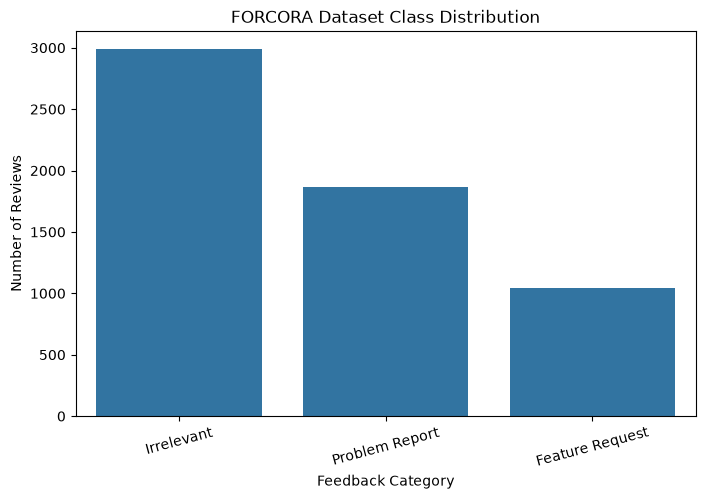

In [14]:
plt.figure(figsize=(8, 5))

sns.countplot(data=clean_df, x="label")

plt.title("FORCORA Dataset Class Distribution")
plt.xlabel("Feedback Category")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=15)

plt.show()

In [15]:
clean_df["review_length"] = clean_df["data"].astype(str).str.len()

clean_df["review_length"].describe()

count    5895.000000
mean      103.956743
std       117.530448
min         1.000000
25%        25.000000
50%        61.000000
75%       141.000000
max      1798.000000
Name: review_length, dtype: float64

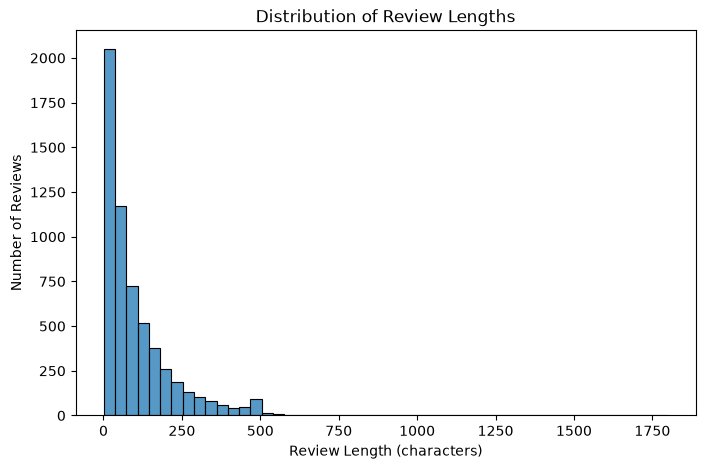

In [19]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=clean_df,
    x="review_length",
    bins=50
)

plt.title("Distribution of Review Lengths")
plt.xlabel("Review Length (characters)")
plt.ylabel("Number of Reviews")

plt.show()